In [1]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# Function to calculate RSI (Relative Strength Index)
def calculate_rsi(data, window=14):
    delta = data['Close'].diff()
    gain = np.where(delta > 0, delta, 0).flatten()
    loss = np.where(delta < 0, -delta, 0).flatten()
    
    avg_gain = pd.Series(gain, index=data.index).rolling(window=window, min_periods=1).mean()
    avg_loss = pd.Series(loss, index=data.index).rolling(window=window, min_periods=1).mean()
    
    rs = avg_gain / (avg_loss + 1e-10)  # Avoid division by zero
    rsi = 100 - (100 / (1 + rs))
    
    return rsi

In [3]:
# Download historical stock data
ticker = "AAPL"
start_date = "2020-01-01"
end_date = "2025-03-28"
data = yf.download(ticker, start=start_date, end=end_date)

if data.empty:
    raise ValueError("Error: No data downloaded. Check the ticker symbol or date range.")

YF.download() has changed argument auto_adjust default to True


[*********************100%***********************]  1 of 1 completed


In [4]:
# Calculate RSI
data['RSI'] = calculate_rsi(data)

# Define trading strategy
data['Buy Signal'] = data['RSI'] < 30
data['Sell Signal'] = data['RSI'] > 70

In [5]:
# Apply cooldown to filter signals
cooldown = 5
data['Filtered Buy'] = (data['Buy Signal'] & ~data['Buy Signal'].shift(cooldown, fill_value=False))
data['Filtered Sell'] = (data['Sell Signal'] & ~data['Sell Signal'].shift(cooldown, fill_value=False))

In [6]:
# Debugging
print("Data preview:")
print(data.head())
print("Data shape:", data.shape)
print("RSI NaN count:", data['RSI'].isna().sum())
print("Buy Signal count:", data['Buy Signal'].sum())
print("Sell Signal count:", data['Sell Signal'].sum())

Data preview:
Price           Close       High        Low       Open     Volume        RSI  \
Ticker           AAPL       AAPL       AAPL       AAPL       AAPL              
Date                                                                           
2020-01-02  72.716064  72.776591  71.466805  71.721011  135480400   0.000000   
2020-01-03  72.009132  72.771760  71.783977  71.941343  146322800   0.000000   
2020-01-06  72.582924  72.621661  70.876090  71.127881  118387200  44.802135   
2020-01-07  72.241539  72.849216  72.021223  72.592586  108872000  35.373190   
2020-01-08  73.403656  73.706287  71.943766  71.943766  132079200  62.347986   

Price      Buy Signal Sell Signal Filtered Buy Filtered Sell  
Ticker                                                        
Date                                                          
2020-01-02       True       False         True         False  
2020-01-03       True       False         True         False  
2020-01-06      False       Fa

In [7]:
# Check if the data is still valid
if data.empty:
    print("Error: All data removed after dropna().")
else:
    print("Data ready for plotting.")

Data ready for plotting.


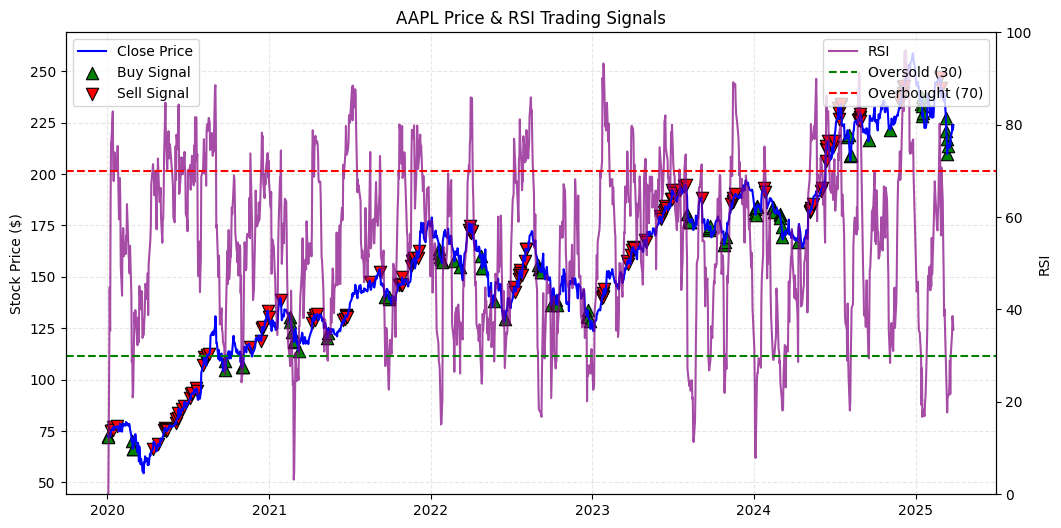

In [8]:
# Plot combined graph
fig, ax1 = plt.subplots(figsize=(12, 6))
ax2 = ax1.twinx()

# Plot stock price
ax1.plot(data.index, data['Close'], label='Close Price', color='blue', linewidth=1.5)
ax1.scatter(data.index[data['Filtered Buy']], data['Close'][data['Filtered Buy']],
            marker='^', color='green', edgecolors='black', linewidth=0.8, s=80, label='Buy Signal')
ax1.scatter(data.index[data['Filtered Sell']], data['Close'][data['Filtered Sell']],
            marker='v', color='red', edgecolors='black', linewidth=0.8, s=80, label='Sell Signal')
ax1.set_ylabel("Stock Price ($)")
ax1.set_title(f"{ticker} Price & RSI Trading Signals")
ax1.legend(loc='upper left')
ax1.grid(True, linestyle='--', alpha=0.3)

# Plot RSI on secondary y-axis
ax2.plot(data.index, data['RSI'], label='RSI', color='purple', linewidth=1.5, alpha=0.7)
ax2.axhline(30, linestyle="--", color="green", label="Oversold (30)")
ax2.axhline(70, linestyle="--", color="red", label="Overbought (70)")
ax2.set_ylim(0, 100)
ax2.set_ylabel("RSI")
ax2.legend(loc='upper right')

plt.show()